# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'Solo Project',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Kabir Minhas', 'github': 'Kminhas21'},
        {'name': 'Kabir Minhas', 'github': 'Kminhas21'},   # solo project; listed twice to match CHARTER.md
    ],
    'repo_url': 'https://github.com/Kminhas21/walmart-hurrican-project',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/Kminhas21/walmart-hurrican-project/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Kabir Minhas',           # nice to have
    'meeting_time': '6:30pm Tuesday',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': [
        "store_id has 60 spellings for 12 stores (case, '_' vs '-', missing hyphen, leading spaces)",
        'unit_price is stored as text; 3,026 values start with $ and some are padded with spaces',
        'timestamp is missing for 886 rows and appears in 5 different formats',
        'the same 20 products are spread over 45 SKUs and 63 product_name spellings (Pop-Tarts alone has 4 SKUs)',
        'category has 37 spellings for 10 real categories; 130 rows have a negative quantity; 30 exact duplicate rows',
    ],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
import subprocess

REPO_PATH = '..'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

46eb1ea Edited the Midterm Checkpoint and restructured the project folder


### 1 — Your cleaning pipeline as functions

Cleaning is split into one function per decision. Each logs what it did to `DECISION_LOG`. `clean_transactions()` runs them in order, and `clean_stores()` cleans the store file. Row counts before and after are printed at the bottom.

In [3]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})

CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)

def clean_stores():
    s = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'), dtype={'zip_code': str})
    n0 = len(s)
    s['store_id'] = (s['store_id'].str.strip().str.upper().str.replace('_', '-', regex=False)
                     .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    s = s.drop_duplicates('store_id').reset_index(drop=True)
    log_decision('stores', 'canonicalise store_id and drop duplicate store rows', n0 - len(s), n0, len(s))
    changed = int((s['state'] != 'FL').sum())
    s['state'] = 'FL'
    log_decision('stores', "normalise state ('Florida', 'Fla.') to 'FL'", changed, len(s), len(s))
    # Tallahassee has no coordinates; approximate city-centre values filled in (needed for the weather call)
    fill = {'FL-619': (30.4383, -84.2807)}
    for sid, (lat, lon) in fill.items():
        m = (s['store_id'] == sid) & s['latitude'].isna()
        s.loc[m, ['latitude', 'longitude']] = (lat, lon)
    log_decision('stores', 'fill missing lat/lon for Tallahassee (FL-619) with approximate city-centre coordinates', len(fill), len(s), len(s))
    return s

raw_tx = load_transactions()
print('transactions rows before cleaning:', len(raw_tx))
tx_clean = clean_transactions()
print('transactions rows after cleaning: ', len(tx_clean), f'({len(raw_tx) - len(tx_clean)} rows removed)')
stores = clean_stores()
joined = tx_clean.merge(stores, on='store_id', how='left', validate='many_to_one', indicator=True)
assert len(joined) == len(tx_clean) and (joined['_merge'] == 'both').all(), 'some transactions did not match a store'
print('store join check: all', len(joined), 'transactions matched one of', len(stores), 'stores')
ts = tx_clean['timestamp'].dropna()
assert ts.dt.year.eq(2024).all() and ts.dt.month.eq(9).all()
assert tx_clean['transaction_id'].is_unique and (tx_clean['quantity'] > 0).all()
tx_clean.head()

transactions rows before cleaning: 25562
transactions rows after cleaning:  25402 (160 rows removed)
store join check: all 25402 transactions matched one of 12 stores


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,product_name_raw
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PEANUT BUTTER
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,Grocery,1,2.02,CANNED SOUP
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,Toilet Paper 12-Roll
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,Roku Streaming Stick
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcohol,3,18.82,Light Beer 24pk


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [4]:
import pandas as pd
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
decision_log = pd.DataFrame(DECISION_LOG)
decision_log

,step,decision,rows_touched,rows_before,rows_after
0,missing,"strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)",0,25562,25562
1,duplicates,drop exact duplicate rows (keep first),30,25562,25532
2,duplicates,drop repeated transaction_id (keep first),0,25532,25532
3,unit_price,"remove '$', cast text -> float",3026,25532,25532
4,unit_price,values that still failed numeric cast -> NaN,0,25532,25532
5,quantity,drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed),130,25532,25402
6,timestamp,parse 5 mixed formats into one datetime (naive local time); 0 unparseable,24521,25402,25402
7,timestamp,missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed,881,25402,25402
8,store_id,"uppercase, strip, '_'/missing '-' -> canonical 'FL-###'",3590,25402,25402
9,category,collapse 37 spellings into 10 canonical categories,18649,25402,25402


**Judgement calls (no disagreement yet, solo project):** negative quantities were dropped rather than sign-flipped (nothing marks them as returns), and the 881 rows with no timestamp were kept but are excluded from date-based work instead of being imputed. The `rows_touched` for the missing-values step counts cells that held a blank/NULL/N-A token; real `NaN` timestamps are counted in the timestamp step.

### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [5]:
def build_sku_map(df):
    """Group SKUs that share product names (union-find over sku <-> normalized name)."""
    names = df[['sku', 'product_name']].dropna().assign(name=lambda d: d['product_name'].str.lower().str.strip())
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in names[['sku', 'name']].drop_duplicates().itertuples(index=False):
        parent[find(('sku', sku))] = find(('name', name))
    names['group'] = names['sku'].map(lambda s: find(('sku', s)))
    sku_group = names.drop_duplicates('sku').set_index('sku')['group']
    ids = {g: i + 1 for i, g in enumerate(sorted(sku_group.unique(), key=str))}
    # canonical name = most common mixed-case product_name in the group (skips ALL-CAPS / lowercase variants)
    mixed = names[~names['product_name'].str.isupper() & ~names['product_name'].str.islower()]
    top_name = (mixed.assign(pid=mixed['group'].map(ids)).groupby('pid')['product_name']
                .agg(lambda s: s.str.strip().value_counts().idxmax()))
    out = pd.DataFrame({'sku': sku_group.index, 'canonical_id': sku_group.map(ids).values})
    out['canonical_name'] = out['canonical_id'].map(top_name)
    return out.sort_values(['canonical_id', 'sku']).reset_index(drop=True)

sku_map = build_sku_map(tx_clean)
sizes = sku_map.groupby(['canonical_id', 'canonical_name']).size().sort_values(ascending=False)
print('distinct SKUs at start:', sku_map['sku'].nunique())
print('canonical products now:', sku_map['canonical_id'].nunique())
print('largest consolidated group:', sizes.index[0][1], f'({sizes.iloc[0]} SKUs)')

pt_id = sku_map.loc[sku_map['canonical_name'].str.contains('Pop-Tarts'), 'canonical_id'].iloc[0]
print('\nPop-Tarts mapping:'); print(sku_map[sku_map['canonical_id'] == pt_id].to_string(index=False))
pt_names = tx_clean.loc[tx_clean['sku'].isin(sku_map.loc[sku_map['canonical_id'] == pt_id, 'sku']), 'product_name_raw']
print('\nraw spellings merged into it:'); print(pt_names.value_counts())

tx_clean = tx_clean.merge(sku_map, on='sku', how='left')
assert tx_clean['canonical_id'].notna().all()
d = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.date)
pt = d[d['canonical_id'] == pt_id]
print('\nPop-Tarts avg daily units, best single SKU:', round(pt.groupby(['day', 'sku'])['quantity'].sum().groupby('sku').mean().max(), 1))
print('Pop-Tarts avg daily units, consolidated:    ', round(pt.groupby('day')['quantity'].sum().mean(), 1))

distinct SKUs at start: 45
canonical products now: 20
largest consolidated group: Pop-Tarts Strawberry (4 SKUs)

Pop-Tarts mapping:
          sku  canonical_id       canonical_name
POPTART-STRAW            16 Pop-Tarts Strawberry
        PT-12            16 Pop-Tarts Strawberry
PT_STRAWBERRY            16 Pop-Tarts Strawberry
   SKU#459812            16 Pop-Tarts Strawberry

raw spellings merged into it:
product_name_raw
Pop-Tarts Strawberry      668
POPTART-STRAWBERRY        383
Pop Tarts - Strawberry    356
pop-tarts strawberry      327
Strawberry Pop-Tart       319
Name: count, dtype: int64

Pop-Tarts avg daily units, best single SKU: 44.4
Pop-Tarts avg daily units, consolidated:     166.8


### 4 — One working weather API call

**Source:** Open-Meteo historical archive, base URL `https://archive-api.open-meteo.com/v1/archive` (free, no key). One call per store location (12), hourly temperature, wind speed, wind gusts, precipitation and sea-level pressure.

**Timezones:** the API is asked for **UTC**, and the code converts it to `America/New_York`. The sales timestamps are naive local Eastern time (the brief calls it EST; in September it is actually EDT, UTC-4). The join key is the converted `time_local`. The call retries with exponential backoff and raises if it never succeeds.

In [6]:
import time, requests

WEATHER_URL = 'https://archive-api.open-meteo.com/v1/archive'
WEATHER_VARS = ['temperature_2m', 'wind_speed_10m', 'wind_gusts_10m', 'precipitation', 'pressure_msl']

def fetch_weather(lat, lon, start, end, retries=4, backoff=2):
    """Hourly weather from Open-Meteo for one point. Retries with exponential backoff and fails loudly."""
    params = dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                  hourly=','.join(WEATHER_VARS), timezone='UTC')   # request UTC, convert ourselves
    last = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(WEATHER_URL, params=params, timeout=30)
            r.raise_for_status()
            df = pd.DataFrame(r.json()['hourly']).rename(columns={'time': 'time_utc'})
            df['time_utc'] = pd.to_datetime(df['time_utc'])
            df['time_local'] = (df['time_utc'].dt.tz_localize('UTC')
                                .dt.tz_convert('America/New_York').dt.tz_localize(None))
            df['source'] = 'open-meteo-archive'
            return df
        except (requests.RequestException, KeyError, ValueError) as e:
            last = e
            print(f'attempt {attempt}/{retries} failed: {e}')
            time.sleep(backoff ** attempt)
    raise RuntimeError(f'weather API failed after {retries} attempts: {last}')

# pull Aug 31 - Oct 1 UTC so every local September hour is covered after the UTC -> Eastern shift
frames = []
for r in stores.itertuples():
    w = fetch_weather(r.latitude, r.longitude, '2024-08-31', '2024-10-01')
    w.insert(0, 'store_id', r.store_id)
    frames.append(w)
weather = pd.concat(frames, ignore_index=True)
weather = weather[(weather['time_local'] >= '2024-09-01') & (weather['time_local'] < '2024-10-01')]
print('weather rows:', len(weather), '| stores:', weather['store_id'].nunique(), '| rows per store:', weather.groupby('store_id').size().unique())
print('missing values:', int(weather.isna().sum().sum()))

# join check: every sales day must have weather
days_sales, days_weather = set(tx_clean['timestamp'].dropna().dt.date), set(weather['time_local'].dt.date)
assert not (days_sales - days_weather), 'sales days without weather'
print('join check passed:', len(days_sales), 'sales days all covered by weather')
weather.head()

weather rows: 8640 | stores: 12 | rows per store: [720]
missing values: 0
join check passed: 30 sales days all covered by weather


,store_id,time_utc,temperature_2m,wind_speed_10m,wind_gusts_10m,precipitation,pressure_msl,time_local,source
28,FL-239,2024-09-01 04:00:00,24.8,7.9,14.8,0.0,1015.2,2024-09-01 00:00:00,open-meteo-archive
29,FL-239,2024-09-01 05:00:00,24.4,5.5,13.0,0.0,1015.0,2024-09-01 01:00:00,open-meteo-archive
30,FL-239,2024-09-01 06:00:00,24.1,5.8,9.0,0.0,1014.5,2024-09-01 02:00:00,open-meteo-archive
31,FL-239,2024-09-01 07:00:00,23.9,5.4,10.1,0.0,1014.0,2024-09-01 03:00:00,open-meteo-archive
32,FL-239,2024-09-01 08:00:00,23.7,4.9,8.6,0.0,1013.8,2024-09-01 04:00:00,open-meteo-archive


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

days: 30 | zero days: 0 | max/median: 3.41


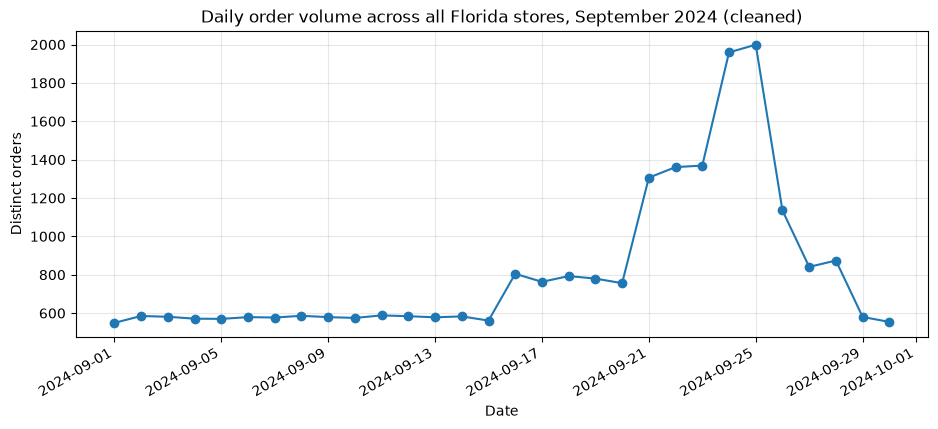

In [7]:
import matplotlib.pyplot as plt

dated = tx_clean.dropna(subset=['timestamp'])
daily = dated.groupby(dated['timestamp'].dt.date)['transaction_id'].nunique()
print(f'days: {len(daily)} | zero days: {int((daily == 0).sum())} | max/median: {daily.max() / daily.median():.2f}')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, marker='o')
ax.set_title('Daily order volume across all Florida stores, September 2024 (cleaned)')
ax.set_xlabel('Date'); ax.set_ylabel('Distinct orders')
ax.grid(alpha=.3); fig.autofmt_xdate(); plt.show()

No zero days. Volume sits on a flat baseline of about 580 orders/day until Sept 15, steps up on Sept 16 (about 790), again on Sept 21 (about 1,350), peaks at about 2,000 on Sept 24-25, then drops back to baseline by Sept 29. That is the shape of a pre-landfall surge, not a pipeline bug. The 881 rows with no timestamp are not in this chart.

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [8]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': bool(result.stdout.strip()),   # True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': len(tx_clean),
    'decisions_logged': len(DECISION_LOG),
    'canonical_products': int(sku_map['canonical_id'].nunique()),
    'weather_api_rows': len(weather),
    'notebook_runs_clean': True,        # Restart and Run All completed with no errors
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25402
  done - decisions_logged = 13
  done - canonical_products = 20
  done - weather_api_rows = 8640
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** the weather join for Question 3. Weather is hourly UTC (converted to Eastern) and sales timestamps are naive local time, so an unnoticed offset or DST error would shift every hourly join and manufacture, or hide, the lag between storm escalation and buying spikes. Related: 881 transactions have no timestamp, so hourly and daily sales are slightly understated.

**Plan, with an owner and a date:** Kabir Minhas, by Wed Nov 4: check the alignment empirically by comparing each store's hourly sales profile against sunrise/overnight weather hours, confirm a known event (the late-September wind peak) lands on the right local day, and write the check as an assertion in the join function. This is a solo project, so there is no teammate to cross-check, and the other risk is simply time.

### 8 — Where each question stands

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | not started (clean dates and categories are ready; the daily chart above shows a late-month rise) | Kabir Minhas |
| Q2 SKU consolidation | in progress: 45 SKUs consolidated into 20 products and a Pop-Tarts before/after preview | Kabir Minhas |
| Q3 weather correlation | in progress: API call works, timezone converted, join row-count check passes; correlation and lag not started | Kabir Minhas |
| Q4 store and geography | not started (store ids join cleanly, coordinates fixed) | Kabir Minhas |
| Q5 signal or artifact | not started | Kabir Minhas |